Evaluation du modèle avant et après adaptation

Pour évaluer le modèle, on a deux critères :
- Classifications des actions. Chaque action donné par le système est labelisée via un "type" qui peut être
Enonciation;
Début;
Action.Valide;
Action.Invalide;
Action.Ambigue;
Action.Incohérente;
Exploration;
Fin. Cela nous fait 8 classes.

- la qualité du game master. Cela va mesurer si la réponse narrative respecte les règles établies du jeu.


Pour mesurer le avant et après adaptation, on va regarder l'indicateur de Parsing Rate qui va donner les fois où le modèle IA va générer un JSON parfaitement valide, l'accuracy qui va quantifier le nombre de prédictions correctes par rapport au total et le macro F1 qui va calculer la précision moyenne, beaucoup plus efficaace dans notre cas au vue des proportions de types et labels plus élevées chez Action.Valide que chez Fin par exemple.



Pour mesurer et évaluer le modèle, ce qui serait bien est de faire le test sans le fine tuning sur le jeu de test de 79 exemples du Dataset TEST. On récupère les scores reçus puis ensuite on fait passer le modèle fintuné directement sur le même dataset et on reprend les scores une nouvelles fois. A la fin, on regarder et on constate la différence entre le avant et après adaptation du modèle.


Clonage du repo

In [2]:

import subprocess
from pathlib import Path

REPO_URL = "https://github.com/2ec3/NLP_narrative-game.git"
BRANCH = "Abdellah"
PROJECT_DIR = Path("/content/nlp-narrative-game-cy-tech-2026-v3")

if PROJECT_DIR.exists() and (PROJECT_DIR / ".git").exists():
    subprocess.run(
        ["git", "-C", str(PROJECT_DIR), "fetch", "origin"],
        check=True
    )
    subprocess.run(
        ["git", "-C", str(PROJECT_DIR), "checkout", BRANCH],
        check=True
    )
    subprocess.run(
        ["git", "-C", str(PROJECT_DIR), "pull", "--ff-only", "origin", BRANCH],
        check=True
    )
else:
    subprocess.run(
        ["git", "clone", "--branch", BRANCH, REPO_URL, str(PROJECT_DIR)],
        check=True
    )

print("Projet :", PROJECT_DIR)
print("Branche :", BRANCH)
print("Dépôt prêt.")


Projet : /content/nlp-narrative-game-cy-tech-2026-v3
Branche : Abdellah
Dépôt prêt.


## Installer les dépendances

In [3]:
%pip install -q "transformers>=4.45" peft accelerate scikit-learn pandas matplotlib seaborn

In [4]:
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## Imports et configuration

In [ ]:
import os
import gc
import json
import time
import random
import platform
import re
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_recall_fscore_support, classification_report,
    confusion_matrix
)
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

BASE_MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
MAX_NEW_TOKENS = 512
DO_SAMPLE = True
TEMPERATURE = 1  # utilisé uniquement si DO_SAMPLE=True
TOP_K = 30
TOP_P = 0.8
RUN_NARRATIVE_ONLY = True

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.15
PyTorch: 2.11.0+cu130
CUDA disponible: True
GPU: Tesla T4


## Trouver le jeu de test et le projet

In [6]:
# Chemins du projet cloné depuis GitHub
PROJECT_DIR = Path("/content/nlp-narrative-game-cy-tech-2026-v3")

TEST_FILE = PROJECT_DIR / "datasets" / "test.json"

# Adaptateur V3
ADAPTER_DIR = (
    PROJECT_DIR
    / "model_adapter"
    / "adapter_r8_lr2e-4v3"
)

# Vérifier que tous les fichiers nécessaires existent
if not TEST_FILE.is_file():
    raise FileNotFoundError(
        f"Jeu de test introuvable : {TEST_FILE}"
    )

if not (ADAPTER_DIR / "adapter_config.json").is_file():
    raise FileNotFoundError(
        f"Configuration de l'adaptateur introuvable : {ADAPTER_DIR}"
    )

if not (
    (ADAPTER_DIR / "adapter_model.safetensors").is_file()
    or (ADAPTER_DIR / "adapter_model.bin").is_file()
):
    raise FileNotFoundError(
        f"Poids de l'adaptateur introuvables : {ADAPTER_DIR}"
    )

print("Projet :", PROJECT_DIR)
print("Jeu de test :", TEST_FILE)
print("Adaptateur V3 :", ADAPTER_DIR)
print("Tous les fichiers nécessaires sont présents.")


Projet : /content/nlp-narrative-game-cy-tech-2026-v3
Jeu de test : /content/nlp-narrative-game-cy-tech-2026-v3/datasets/test.json
Adaptateur V3 : /content/nlp-narrative-game-cy-tech-2026-v3/model_adapter/adapter_r8_lr2e-4v3
Tous les fichiers nécessaires sont présents.


## Charger le jeu de test

In [7]:
def load_json_records(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        payload = json.load(f)
    if isinstance(payload, list):
        records = payload
    elif isinstance(payload, dict):
        records = None
        for key in ("data", "examples", "records", "test"):
            if isinstance(payload.get(key), list):
                records = payload[key]
                break
        if records is None:
            raise ValueError(
                f"Le JSON est un objet, mais aucune liste n'a été trouvée dans data/examples/records/test. "
                f"Clés présentes : {list(payload.keys())}"
            )
    else:
        raise TypeError("Format JSON inattendu : une liste ou un objet contenant une liste est attendu.")
    return records

test_records = load_json_records(TEST_FILE)
print("Nombre d'exemples :", len(test_records))
print("Type du premier exemple :", type(test_records[0]).__name__ if test_records else "jeu vide")
if test_records:
    print("Clés du premier exemple :", list(test_records[0].keys()))
    print("Label brut du premier exemple :", test_records[0].get("type"))
    print("Nombre de messages :", len(test_records[0].get("messages", [])))

if not test_records:
    raise ValueError("Le jeu de test est vide.")

Nombre d'exemples : 79
Type du premier exemple : dict
Clés du premier exemple : ['messages', 'type']
Label brut du premier exemple : exploration
Nombre de messages : 4


4. Normaliser les labels en huit classes

Le dataset contient des sous-types (`fin - victoire`, `action.valide - reformulation`) et des variantes orthographiques. On ramène les sous-types aux huit classes principales pour éviter des données solitaires.

In [8]:
CLASSES = [
    "énonciation",
    "début",
    "action.valide",
    "action.invalide",
    "action.ambigue",
    "action.incohérente",
    "exploration",
    "fin",
]

def normalize_label(value):
    if value is None:
        return None
    s = str(value).strip().lower()
    s = s.replace("_", ".").replace(" ", ".")
    s = s.replace("é", "e").replace("è", "e").replace("ê", "e")
    s = s.replace("à", "a").replace("â", "a")
    s = s.replace("ï", "i").replace("î", "i")
    s = s.replace("ç", "c")
    s = re.sub(r"\.+", ".", s).strip(".")
    mapping = {
        "enonciation": "énonciation",
        "enonciation.": "énonciation",
        "debut": "début",
        "action.valide": "action.valide",
        "action.invalide": "action.invalide",
        "action.ambigue": "action.ambigue",
        "action.incoherente": "action.incohérente",
        "exploration": "exploration",
        "fin": "fin",
    }
    return mapping.get(s, str(value).strip())

for i, ex in enumerate(test_records):
    if not isinstance(ex, dict):
        raise TypeError(f"Exemple {i} n'est pas un objet JSON.")
    ex["_gold_type"] = normalize_label(ex.get("type"))

label_counts = pd.Series([x["_gold_type"] for x in test_records]).value_counts(dropna=False)
display(label_counts.rename_axis("label").to_frame("count"))

unknown_labels = sorted({
    str(x["_gold_type"]) for x in test_records
    if x["_gold_type"] not in CLASSES
})
print("Labels absents des 8 classes :", unknown_labels)

,count
label,
action.valide,31
action.incohérente,13
exploration,11
action.invalide,7
énonciation,4
fin - objectif accompli après dernier obstacle,1
fin,1
début,1
action.valide - reformulation simple,1


Labels absents des 8 classes : ['action partiellement valide', 'action.ambiguë - action hors choix', 'action.ambiguë - interaction', 'action.incohérente après progression', 'action.invalide - intention différente', 'action.valide - intention implicite', 'action.valide - reformulation simple', 'fin - conclusion narrative', 'fin - décision du joueur', 'fin - objectif accompli après dernier obstacle']


## Visualiser la répartition des classes

,classe,nombre,pourcentage
0,énonciation,4,5.06
1,début,1,1.27
2,action.valide,31,39.24
3,action.invalide,7,8.86
4,action.ambigue,1,1.27
5,action.incohérente,13,16.46
6,exploration,11,13.92
7,fin,1,1.27


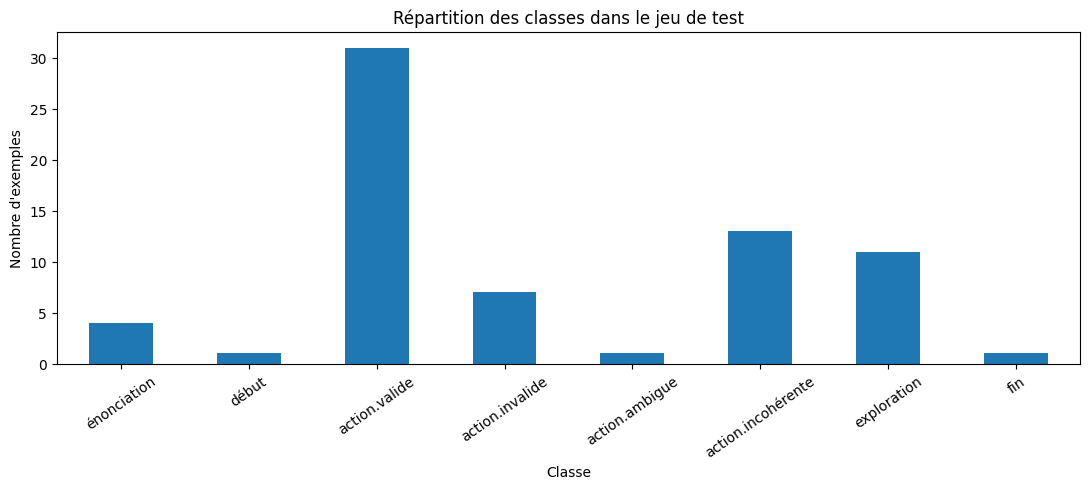

In [9]:
# Récupérer les vraies classes depuis le dataset de test
y_true = [ex["_gold_type"] for ex in test_records]

# Calculer la distribution des 8 classes
distribution = (
    pd.Series(y_true, name="classe")
    .value_counts()
    .reindex(CLASSES, fill_value=0)
    .rename_axis("classe")
    .reset_index(name="nombre")
)

# Calculer les pourcentages
distribution["pourcentage"] = (
    distribution["nombre"] / len(y_true) * 100
).round(2)

display(distribution)

# Visualisation
ax = distribution.plot(
    kind="bar",
    x="classe",
    y="nombre",
    legend=False,
    figsize=(11, 5),
    rot=35,
    title="Répartition des classes dans le jeu de test"
)

ax.set_xlabel("Classe")
ax.set_ylabel("Nombre d'exemples")
plt.tight_layout()
plt.show()

## Construire les prompts

In [10]:
OUTPUT_INSTRUCTION = (
    "\n\nPour cette évaluation, réponds uniquement avec un objet JSON valide, sans Markdown ni texte autour. "
    "La valeur de type doit être exactement l'une des classes suivantes : "
    + ", ".join(CLASSES)
    + ". La réponse doit respecter les règles du jeu et rester concise."
)

def clean_messages(raw_messages):
    cleaned = []
    if not isinstance(raw_messages, list):
        return cleaned
    for m in raw_messages:
        if not isinstance(m, dict):
            continue
        role = m.get("role")
        content = m.get("content")
        if role not in {"system", "user", "assistant"}:
            continue
        if content is None:
            continue
        if not isinstance(content, str):
            content = json.dumps(content, ensure_ascii=False)
        cleaned.append({"role": role, "content": content})
    return cleaned

def build_structured_messages(example):
    messages = clean_messages(example.get("messages", []))
    if not messages:
        return None
    # Ajouter la consigne au message système existant, sinon en créer un.
    system_indices = [i for i, m in enumerate(messages) if m["role"] == "system"]
    if system_indices:
        idx = system_indices[0]
        messages[idx]["content"] = messages[idx]["content"].rstrip() + OUTPUT_INSTRUCTION
    else:
        messages.insert(0, {
            "role": "system",
            "content": "Tu es le Game Master d'un jeu de rôle fantasy en solo." + OUTPUT_INSTRUCTION
        })
    return messages

prepared = []
for idx, ex in enumerate(test_records):
    msgs = build_structured_messages(ex)
    if msgs is None:
        print(f"Exemple ignoré (pas de messages valides) : index={idx}")
        continue
    prepared.append({
        "example_id": idx,
        "gold_type": ex["_gold_type"],
        "messages": msgs,
        "raw_example": ex,
    })

print(f"Exemples utilisables : {len(prepared)} / {len(test_records)}")

Exemples utilisables : 79 / 79


## Fonctions de générations et de parsing

Par rapport à la latence, la première génération sera toujours plus lente car elle doit s'initialiser. On doit prendre cette valeur en compte pour l'interpreter avec attention.

In [ ]:
def load_base_model():
    tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_ID)
    model = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL_ID,
        torch_dtype="auto",
        device_map="auto",
    )
    model.eval()
    return tokenizer, model


def load_finetuned_model(adapter_dir):
    if adapter_dir is None:
        raise FileNotFoundError("ADAPTER_DIR n'est pas défini.")

    adapter_dir = Path(adapter_dir)

    if not (adapter_dir / "adapter_config.json").is_file():
        raise FileNotFoundError(
            f"adapter_config.json absent de {adapter_dir}"
        )

    # Charger le tokenizer fourni avec l'adaptateur lorsqu'il existe,
    # notamment pour utiliser son chat_template.jinja.
    tokenizer_source = (
        str(adapter_dir)
        if (adapter_dir / "tokenizer_config.json").is_file()
        else BASE_MODEL_ID
    )
    tokenizer = AutoTokenizer.from_pretrained(tokenizer_source)

    base = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL_ID,
        torch_dtype="auto",
        device_map="auto",
    )

    model = PeftModel.from_pretrained(base, str(adapter_dir))
    model.eval()

    print("Modèle de base :", BASE_MODEL_ID)
    print("Adaptateur LoRA :", adapter_dir)
    print("Tokenizer :", tokenizer_source)

    return tokenizer, model


def generate_one(model, tokenizer, messages, max_new_tokens=MAX_NEW_TOKENS):
    rendered = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    inputs = tokenizer(rendered, return_tensors="pt")
    input_device = next(model.parameters()).device
    inputs = {k: v.to(input_device) for k, v in inputs.items()}

    generation_kwargs = {
        "max_new_tokens": max_new_tokens,
        "do_sample": DO_SAMPLE,
        "pad_token_id": tokenizer.eos_token_id,
        "eos_token_id": tokenizer.eos_token_id,
    }
    if DO_SAMPLE:
        generation_kwargs["temperature"] = TEMPERATURE
        generation_kwargs["top_k"] = TOP_K
        generation_kwargs["top_p"] = TOP_P

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.inference_mode():
        output_ids = model.generate(**inputs, **generation_kwargs)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    prompt_len = inputs["input_ids"].shape[1]
    new_tokens = output_ids[0, prompt_len:]
    text_out = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
    return text_out, elapsed, int(new_tokens.numel())

def parse_json_strict(raw_text):
    try:
        obj = json.loads(raw_text.strip())
        return obj, True
    except Exception:
        return None, False

def validate_schema(obj):
    if not isinstance(obj, dict):
        return False
    label = normalize_label(obj.get("type"))
    response = obj.get("response")
    return label in CLASSES and isinstance(response, str) and bool(response.strip())

def evaluate_model(model_name, model, tokenizer, examples):
    rows = []
    for i, item in enumerate(examples, start=1):
        try:
            raw, latency, token_count = generate_one(model, tokenizer, item["messages"])
            obj, parsed = parse_json_strict(raw)
            schema_ok = validate_schema(obj) if parsed else False
            pred_type = normalize_label(obj.get("type")) if schema_ok else "erreur_de_format"
            response = obj.get("response", "") if schema_ok else ""
            rows.append({
                "model": model_name,
                "example_id": item["example_id"],
                "gold_type": item["gold_type"],
                "predicted_type": pred_type,
                "raw_output": raw,
                "response": response,
                "json_valid": bool(parsed),
                "schema_valid": bool(schema_ok),
                "latency_seconds": latency,
                "generated_tokens": token_count,
                "error": None,
            })
        except Exception as e:
            rows.append({
                "model": model_name,
                "example_id": item["example_id"],
                "gold_type": item["gold_type"],
                "predicted_type": "erreur_de_generation",
                "raw_output": "",
                "response": "",
                "json_valid": False,
                "schema_valid": False,
                "latency_seconds": np.nan,
                "generated_tokens": 0,
                "error": repr(e),
            })
        if i % 10 == 0 or i == len(examples):
            print(f"{model_name}: {i}/{len(examples)}")
    return pd.DataFrame(rows)

## Evaluer la baseline

In [12]:
tokenizer, baseline_model = load_base_model()
baseline_results = evaluate_model("Baseline", baseline_model, tokenizer, prepared)

del baseline_model
del tokenizer
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

display(baseline_results.head(3))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Baseline: 10/79
Baseline: 20/79
Baseline: 30/79
Baseline: 40/79
Baseline: 50/79
Baseline: 60/79
Baseline: 70/79
Baseline: 79/79


,model,example_id,gold_type,predicted_type,raw_output,response,json_valid,schema_valid,latency_seconds,generated_tokens,error
0,Baseline,0,exploration,erreur_de_format,"Action validée.\nChoisissez une action : A, B ...",,False,False,5.724783,17,None
1,Baseline,1,action.valide,erreur_de_format,Action validée - Retrouvé son sac à main qui c...,,False,False,9.198802,96,None
2,Baseline,2,action.valide,erreur_de_format,Objectif atteint : Vous êtes maintenant plus p...,,False,False,3.849186,64,None


## Evaluer le modèle finetuné

In [13]:
if ADAPTER_DIR is None:
    raise FileNotFoundError(
        "Adaptateur LoRA introuvable. Corrige ADAPTER_DIR_OVERRIDE dans la cellule 3, puis relance."
    )

tokenizer, finetuned_model = load_finetuned_model(ADAPTER_DIR)
finetuned_results = evaluate_model("Fine-tuned", finetuned_model, tokenizer, prepared)

del finetuned_model
del tokenizer
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

display(finetuned_results.head(3))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Modèle de base : Qwen/Qwen2.5-1.5B-Instruct
Adaptateur LoRA : /content/nlp-narrative-game-cy-tech-2026-v3/model_adapter/adapter_r8_lr2e-4v3
Tokenizer : /content/nlp-narrative-game-cy-tech-2026-v3/model_adapter/adapter_r8_lr2e-4v3
Fine-tuned: 10/79
Fine-tuned: 20/79
Fine-tuned: 30/79
Fine-tuned: 40/79
Fine-tuned: 50/79
Fine-tuned: 60/79
Fine-tuned: 70/79
Fine-tuned: 79/79


,model,example_id,gold_type,predicted_type,raw_output,response,json_valid,schema_valid,latency_seconds,generated_tokens,error
0,Fine-tuned,0,exploration,erreur_de_format,Action validée.\nChoix A (Traverser l'arche ce...,,False,False,2.793640,27,None
1,Fine-tuned,1,action.valide,erreur_de_format,*Action validée.* Vos doigts ensanglent légère...,,False,False,7.033041,83,None
2,Fine-tuned,2,action.valide,erreur_de_format,"Votre geste est parfait. Plus tard, après avoi...",,False,False,3.816387,43,None


## Métriques principales (essai)

In [14]:
def safe_mean(series):
    return float(series.mean()) if len(series) else float("nan")

def summarize_results(df):
    valid_gold = df["gold_type"].isin(CLASSES)
    sub = df.loc[valid_gold].copy()
    y_true = sub["gold_type"].tolist()
    y_pred = sub["predicted_type"].tolist()

    return {
        "n": int(len(sub)),
        "json_parse_rate": float(sub["json_valid"].mean()) if len(sub) else np.nan,
        "schema_compliance_rate": float(sub["schema_valid"].mean()) if len(sub) else np.nan,
        "accuracy": float(accuracy_score(y_true, y_pred)) if len(sub) else np.nan,
        "balanced_accuracy": float(balanced_accuracy_score(
            y_true, y_pred, adjusted=False
        )) if len(sub) else np.nan,
        "macro_f1": float(f1_score(
            y_true, y_pred, labels=CLASSES, average="macro", zero_division=0
        )) if len(sub) else np.nan,
        "macro_precision": float(precision_recall_fscore_support(
            y_true, y_pred, labels=CLASSES, average="macro", zero_division=0
        )[0]) if len(sub) else np.nan,
        "macro_recall": float(precision_recall_fscore_support(
            y_true, y_pred, labels=CLASSES, average="macro", zero_division=0
        )[1]) if len(sub) else np.nan,
        "median_latency_s": float(sub["latency_seconds"].median()),
        "p95_latency_s": float(sub["latency_seconds"].quantile(0.95)),
        "generation_error_rate": float(sub["error"].notna().mean()),
    }

all_results = pd.concat([baseline_results, finetuned_results], ignore_index=True)
summary = pd.DataFrame([
    {"model": name, **summarize_results(group)}
    for name, group in all_results.groupby("model", sort=False)
])

display(summary.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,model,n,json_parse_rate,schema_compliance_rate,accuracy,balanced_accuracy,macro_f1,macro_precision,macro_recall,median_latency_s,p95_latency_s,generation_error_rate
0,Baseline,69,0.1739,0.0,0.0,0.0,0.0,0.0,0.0,2.2572,9.4525,0.0
1,Fine-tuned,69,0.0870,0.0,0.0,0.0,0.0,0.0,0.0,4.1819,8.8573,0.0


## Rapport par classe

In [15]:
for model_name, df in all_results.groupby("model", sort=False):
    print("\n" + "=" * 80)
    print("RAPPORT :", model_name)
    valid = df[df["gold_type"].isin(CLASSES)]
    print(classification_report(
        valid["gold_type"],
        valid["predicted_type"],
        labels=CLASSES,
        zero_division=0,
        digits=3,
    ))


RAPPORT : Baseline
                    precision    recall  f1-score   support

       énonciation      0.000     0.000     0.000       4.0
             début      0.000     0.000     0.000       1.0
     action.valide      0.000     0.000     0.000      31.0
   action.invalide      0.000     0.000     0.000       7.0
    action.ambigue      0.000     0.000     0.000       1.0
action.incohérente      0.000     0.000     0.000      13.0
       exploration      0.000     0.000     0.000      11.0
               fin      0.000     0.000     0.000       1.0

         micro avg      0.000     0.000     0.000      69.0
         macro avg      0.000     0.000     0.000      69.0
      weighted avg      0.000     0.000     0.000      69.0


RAPPORT : Fine-tuned
                    precision    recall  f1-score   support

       énonciation      0.000     0.000     0.000       4.0
             début      0.000     0.000     0.000       1.0
     action.valide      0.000     0.000     0.000     

## Matrice de confusion

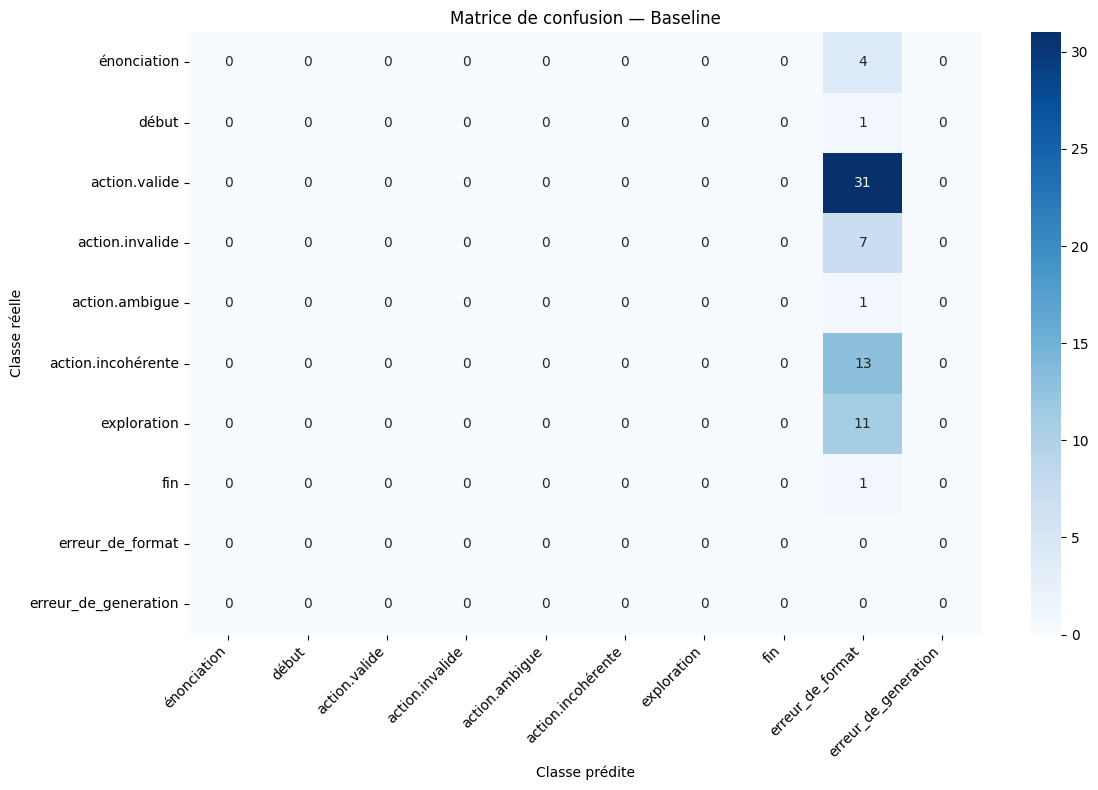

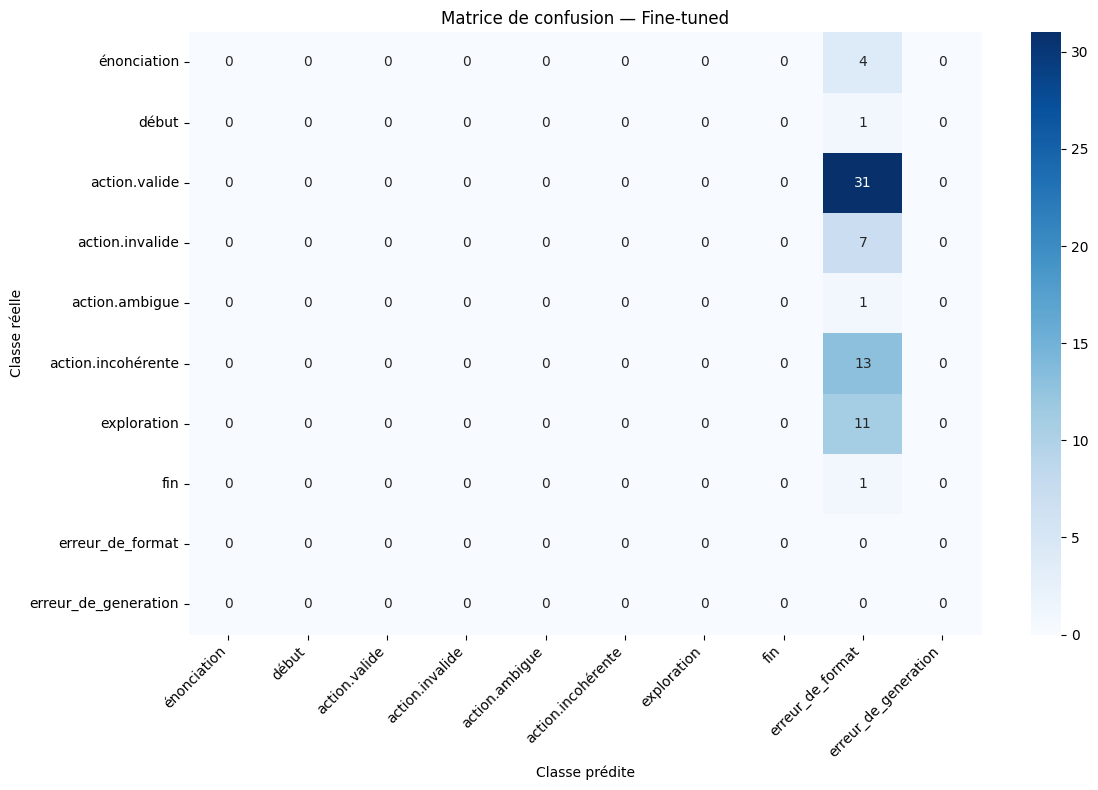

In [16]:
EXTRA_LABELS = ["erreur_de_format", "erreur_de_generation"]
CM_LABELS = CLASSES + EXTRA_LABELS

for model_name, df in all_results.groupby("model", sort=False):
    valid = df[df["gold_type"].isin(CLASSES)]
    cm = confusion_matrix(
        valid["gold_type"],
        valid["predicted_type"],
        labels=CM_LABELS,
    )
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CM_LABELS, yticklabels=CM_LABELS
    )
    plt.title(f"Matrice de confusion — {model_name}")
    plt.xlabel("Classe prédite")
    plt.ylabel("Classe réelle")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

## Comparaison sur de mêmes exemples

In [17]:
if set(all_results["model"]) >= {"Baseline", "Fine-tuned"}:
    compare = summary.set_index("model").T
    compare["delta_finetuned_minus_baseline"] = compare["Fine-tuned"] - compare["Baseline"]
    display(compare.round(4))
else:
    print("Il manque les résultats d'au moins un des deux modèles.")

model,Baseline,Fine-tuned,delta_finetuned_minus_baseline
n,69.0000,69.0000,0.0000
json_parse_rate,0.1739,0.0870,-0.0870
schema_compliance_rate,0.0000,0.0000,0.0000
accuracy,0.0000,0.0000,0.0000
balanced_accuracy,0.0000,0.0000,0.0000
macro_f1,0.0000,0.0000,0.0000
macro_precision,0.0000,0.0000,0.0000
macro_recall,0.0000,0.0000,0.0000
median_latency_s,2.2572,4.1819,1.9247
p95_latency_s,9.4525,8.8573,-0.5953


## Exports des résultats et rapports

In [18]:
OUTPUT_DIR = (
    PROJECT_DIR
    / "evaluation_results"
    / "eval adapter_r8_lr2e-4v3"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dossier de sortie :", OUTPUT_DIR)

run_info = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "base_model_id": BASE_MODEL_ID,
    "adapter_dir": str(ADAPTER_DIR) if ADAPTER_DIR else None,
    "test_file": str(TEST_FILE),
    "n_test_records": len(test_records),
    "n_evaluated": len(prepared),
    "max_new_tokens": MAX_NEW_TOKENS,
    "do_sample": DO_SAMPLE,
    "seed": SEED,
    "python": platform.python_version(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}

all_results.to_csv(OUTPUT_DIR / "predictions_all_models.csv", index=False)
summary.to_csv(OUTPUT_DIR / "metrics_summary.csv", index=False)
with open(OUTPUT_DIR / "run_config.json", "w", encoding="utf-8") as f:
    json.dump(run_info, f, ensure_ascii=False, indent=2)

print("Résultats enregistrés dans :", OUTPUT_DIR)
print("Fichiers :")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.name)

Dossier de sortie : /content/nlp-narrative-game-cy-tech-2026-v3/evaluation_results/eval adapter_r8_lr2e-4v3
Résultats enregistrés dans : /content/nlp-narrative-game-cy-tech-2026-v3/evaluation_results/eval adapter_r8_lr2e-4v3
Fichiers :
- blind_narrative_rubric.csv
- constat.txt
- evaluation_narrative_79_reponses.xlsx
- metrics_summary.csv
- predictions_all_models.csv
- run_config.json


## Préparation de l'évaluation narrative à l'aveugle

In [19]:
wide = all_results.pivot_table(
    index="example_id",
    columns="model",
    values="response",
    aggfunc="first"
).reset_index()

for col in ["Baseline", "Fine-tuned"]:
    if col not in wide.columns:
        wide[col] = ""

rng = random.Random(SEED)
blind_rows = []
for _, row in wide.iterrows():
    a_is_baseline = rng.choice([True, False])
    response_a = row["Baseline"] if a_is_baseline else row["Fine-tuned"]
    response_b = row["Fine-tuned"] if a_is_baseline else row["Baseline"]
    blind_rows.append({
        "example_id": int(row["example_id"]),
        "response_A": response_a,
        "response_B": response_b,
        "respect_regles_A_0_2": "",
        "coherence_A_0_2": "",
        "pertinence_A_0_2": "",
        "immersion_A_0_2": "",
        "concision_A_0_2": "",
        "respect_regles_B_0_2": "",
        "coherence_B_0_2": "",
        "pertinence_B_0_2": "",
        "immersion_B_0_2": "",
        "concision_B_0_2": "",
        "_A_is_baseline": a_is_baseline,
    })

blind_df = pd.DataFrame(blind_rows)
blind_df.to_csv(OUTPUT_DIR / "blind_narrative_rubric.csv", index=False)
print("Grille exportée :", OUTPUT_DIR / "blind_narrative_rubric.csv")
print("Pour une vraie évaluation à l'aveugle, retire/masque la colonne _A_is_baseline pendant la notation.")

Grille exportée : /content/nlp-narrative-game-cy-tech-2026-v3/evaluation_results/eval adapter_r8_lr2e-4v3/blind_narrative_rubric.csv
Pour une vraie évaluation à l'aveugle, retire/masque la colonne _A_is_baseline pendant la notation.
